## 1、构建流程

In [1]:
from operator import add
from typing import TypedDict, Annotated,Literal
import asyncio
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain_community.chat_models import ChatTongyi # pip install dashscope
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.config import get_stream_writer
from langgraph.constants import START, END
from langgraph.graph import StateGraph
from pydantic import BaseModel, Field
from langgraph.types import Send
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain_community.embeddings import DashScopeEmbeddings # pip install langchain-community
from langchain_chroma import Chroma #%pip install langchain-chroma
from langchain_core.prompts import ChatPromptTemplate
from dotenv import load_dotenv
load_dotenv() # 从 .env 文件加载环境变量

c:\Users\21566\anaconda3\envs\ai-langchain1.0\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
C:\Users\21566\AppData\Local\Temp\ipykernel_17748\771569496.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.chat_models import ChatTongyi


True

In [3]:
router_llm = ChatTongyi(model="qwen-plus")
router_llm.invoke("hello")

c:\Users\21566\anaconda3\envs\ai-langchain1.0\Lib\site-packages\langsmith\_internal\_agent_addressing.py:61: LangSmithBetaWarning: Agent addressing (`agent_id` / `agent_environment`) is in beta and is enabled per workspace. A workspace without it rejects the run, so the trace is lost rather than falling back to a project. The behavior may change without notice.
  _warn_once(


AIMessage(content='Hello! How can I help you today? 😊', additional_kwargs={}, response_metadata={'model_name': 'qwen-plus', 'finish_reason': 'stop', 'request_id': '6462742c-2ec5-993c-be4a-5875403b779f', 'token_usage': {'input_tokens': 9, 'output_tokens': 11, 'total_tokens': 20, 'prompt_tokens_details': {'cached_tokens': 0}}}, id='lc_run--01a14373-7fa7-7220-bdd0-09be687ba2db-0', tool_calls=[], invalid_tool_calls=[])

In [4]:
class AgentInput(TypedDict):
    """每个子agent的输入状态"""
    query: str                                # 当前任务类型/状态
    
class AgentOutput(TypedDict):
    """每个子agent的输出"""
    source: Literal["travel_agent", "joke_agent", "couplet_agent", "other_agent"]
    result: str

class Classification(TypedDict):
    """单个路由决策：调用哪个agent以及对应的查询"""
    source: Literal["travel", "joke", "couplet", "other"]
    query: str

class RouterState(TypedDict):
    """主路由状态"""
    query: str # 用户输入
    classifications: list[Classification]
    results: Annotated[list[AgentOutput], add]  # 自动累积结果
    final_answer: str

In [16]:
# 模型的返回类型
class ClassificationOutput(BaseModel):
    classifications:list[Classification] = Field(..., description="分类结果列表")

structured_llm = router_llm.with_structured_output(ClassificationOutput) # 大模型输出的结果要以结构化输出
system_prompt = """
    你是一个路由分类器，请根据用户输入的问题，进行分类，并返回严格的 JSON 格式。
    类型：
    - travel：旅游路线规划、景点推荐、交通查询等。
    - joke：笑话、段子等。
    - couplet：对对联、诗词等。
    - other：其他类型的问题。
    
    规则：
    - 1. 必须严格按照 JSON 格式返回，格式如下：
    {
        "classifications":[
            {
                "source": "travel",
                "query": "我想去北京旅游，推荐一下路线。"
            },
            {
                "source": "joke",
                "query": "请推荐一个郭德纲的相声。"
            }
        ]
    }
    - 2. source 字段必须为上述四个类型之一。
    - 3. query 字段必须为用户输入的问题，不能进行任何修改。
    - 4. 如果无法分类，请返回空 JSON。
    """    
def classify(state:RouterState)->RouterState:
    """根据用户输入的query,分类出对应的任务类型"""
    
    writer = get_stream_writer()
    writer(f"1-node: classify分类节点")
    
    other = RouterState(
        query=state["query"],
        classifications=[Classification(source="other_agent", query=state["query"])],
        results=[],
        final_answer=""
    )
    
    try:
        result = structured_llm.invoke([
            {"role":"assistant", "content":system_prompt},
            {"role":"user", "content":state["query"]}
        ])
        
        writer(f"1-node: classify分类结果: {result}")
        if result is None:
            return other
        return RouterState(
            query=state["query"],
            classifications=result.classifications,
            results=[],
            final_answer=""
        )
    except Exception as e:
        writer(f"1-node: classify分类节点异常: {e}")
        return other

## 2、聊天智能体

In [ ]:
model=init_chat_model("gpt-4o")
joke_agent = create_agent(
    model=model,
    tools=[],
    system_prompt="""
    你是一个笑话智能体，请根据用户输入的问题，返回一个笑话。
    """
)

def joke_node(state: AgentInput)->RouterState:
    """笑话智能体"""
    writer = get_stream_writer()
    writer(f"2-node: joke_node笑话节点")
    response = joke_agent.invoke(
        {
            "messages":[{"role":"user", "content":state["query"]}],
        }
    )
    content = response["messages"][-1].content
    writer(f"2-node: joke_node笑话节点生成的内容: {content}")
    
    
    return {
        "results":[{"source":"joke_agent", "result":content}]
    }

## 3、旅行智能体

In [38]:
_mcp_tools = None # 全局变量，存储高德提供的所有工具
_travel_agent = None

# 单例设计模型，避免重复创建
async def get_mcp_tools():
    global _mcp_tools
    if _mcp_tools is None:
        client = MultiServerMCPClient(
            {
                "amap-maps":{
                    "transport":"streamable-http", 
                    "url":"https://mcp.amap.com/mcp?key=c9ff46af8bc64a009c9b2b7f648bb339"
                }        
        })
        _mcp_tools =await client.get_tools()
    return _mcp_tools
   
async def get_travel_agent():
    global _travel_agent
    if _travel_agent is None:
        tools = await get_mcp_tools()
        _travel_agent = create_agent(
            model=model,
            tools=tools,
            system_prompt="""
            你是一个旅行智能体，请根据用户输入的问题，返回一个旅游路线规划。
            """
        )
        
    return _travel_agent

def travel_node(state: AgentInput)->RouterState:
    """旅行智能体"""
    writer = get_stream_writer()
    writer(f"3-node: travle_node旅行节点")
    
    async def async_travel():
        travel_agent = await get_travel_agent()
        response = await travel_agent.ainvoke({
            "messages":[
                {"role":"user", "content":state["query"]}
            ],
        })
        return response["messages"][-1].content

    result = asyncio.run(async_travel()) # 运行异步函数获取结果
    writer(f"3-node: travle_node旅行节点生成的内容: {result}")
    
    return {
        "results":[{"source":"travel_agent", "result":result}]
    }

## 4、对对联智能体

In [42]:
_vector_store = None
def get_vector_store():
    global _vector_store
    if _vector_store is None:
        embedding_model = DashScopeEmbeddings(model="text-embedding-v1") #使用百炼平台的向量模型
        _vector_store = Chroma(
            persist_directory="./data/vector_db",#向量存储的位置, 默认是以sqlite文件方式存储
            embedding_function=embedding_model, #指定嵌入模型
            collection_name="couplet" #指定集合名称
        )
    
    return _vector_store

from langchain_core.prompts import ChatPromptTemplate
prompt_template = ChatPromptTemplate.from_messages([
    ("system", """
     你是一个专业的对联大师，你的任务是根据用户给出的上联，生成一句下联。
     回答时，可以参考下面的内容：
     {context}
     请用中文回答。
     """),
    ("user", "{text}")
])

def couplet_node(state: AgentInput)->RouterState:
    """对对联智能体"""
    writer = get_stream_writer()
    writer(f"4-node: couplet_node对对联节点")
    
    question = state["query"]
    score_results  = get_vector_store().similarity_search_with_score(question, k=10)
    examples = []
    for doc, _ in score_results:
        examples.append(doc.page_content)
    prompt = prompt_template.invoke({"context": examples, "text": question})
    result = model.invoke(prompt)
    writer(f"4-node: couplet_node对对联节点生成的内容: {result.content}")
    return {
        "results":[{"source":"couplet_agent", "result":result.content}]
    }

## 5、兜底智能体

In [20]:
def other_node(state: AgentInput)->RouterState:
    """其他智能体"""
    writer = get_stream_writer()
    writer(f"5-node: other_node其他智能体")
    return {
        "results":[{"source":"other_agent", "result":"其他节点处理情况。。。。"}]
    }

## 6、汇总节点

In [51]:
def synthesize_node(state: RouterState)->RouterState:
    """汇总节点"""
    writer = get_stream_writer()
    writer(f"6-node: synthesize_node汇总节点")
    
    #拿到上述所有节点的内容，并且拼接在一起交给模型回复！
    # 1. 拿到所有结果
    formatted_results = [f"{r['source']}:{r['result']}" for r in state["results"]]
    final = "最终回复的结果如下：\n".join(formatted_results)    
    # 2. 模型回复
    system_prompt = f"""
    用户提出的问题是：{state["query"]}，请根据以下内容进行综合回复：
    参考内容如下：
    {final}
    
    请用中文回答。
    """
    response = model.invoke(system_prompt)
    writer(f"6-node: synthesize_node汇总节点生成的内容: {response.content}")
    
    return {
        "final_answer":response.content
    }

In [48]:
def route_to_agents(state:RouterState)->list[Send]:
    """根据分类结果，将任务分发给对应的节点"""
    """
    class RouterState(TypedDict):
        query: str # 用户输入
        classifications: list[Classification]
        results: Annotated[list[AgentOutput], add]  # 自动累积结果
        final_answer: str
    """
    results = []
    for classification in state["classifications"]:
        results.append(
            Send(classification["source"], {"query":classification["query"]})
        )
    return results

In [52]:
builder = StateGraph(RouterState)

#添加节点
builder.add_node("classify", classify)
builder.add_node("travel", travel_node)
builder.add_node("joke", joke_node)
builder.add_node("couplet", couplet_node)
builder.add_node("other", other_node)
builder.add_node("synthesize", synthesize_node)

#添加边
builder.add_edge(START, "classify")
builder.add_conditional_edges("classify", route_to_agents, ["travel", "joke", "couplet", "other"])
builder.add_edge("travel", "synthesize")
builder.add_edge("joke", "synthesize")
builder.add_edge("couplet", "synthesize")
builder.add_edge("other", "synthesize")

#添加终点
builder.add_edge("synthesize", END)
# 构建图
graph = builder.compile()

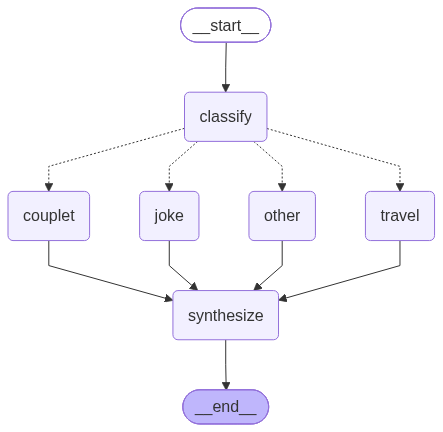

In [24]:
graph

In [54]:
for chunk in graph.stream({"query":"请帮我对一副对联，上联是:好好学习;顺便讲一段郭德纲风格的笑话！"}, stream_mode="custom"):
    print(chunk)

1-node: classify分类节点
1-node: classify分类结果: classifications=[{'source': 'couplet', 'query': '请帮我对一副对联，上联是:好好学习'}, {'source': 'joke', 'query': '顺便讲一段郭德纲风格的笑话！'}]
4-node: couplet_node对对联节点
2-node: joke_node笑话节点
4-node: couplet_node对对联节点生成的内容: 上联：好好学习  
下联：天天向上
2-node: joke_node笑话节点生成的内容: 有这么一个人，姓张，爱吹牛。有一次他跟朋友喝酒，说：“我跟你说啊，我家老祖宗可是特别有名的人物。”朋友一听，来了兴趣：“哦？你祖宗是谁啊？”

张某得意洋洋地说：“我祖宗是诸葛亮！”朋友一脸惊讶：“真的假的？不会吹牛吧？”

张某用力拍了拍胸脯：“绝对真的！我家里还有传家宝呢！”朋友更好奇了：“什么传家宝？”

张某说：“就是诸葛亮发明的空调！”朋友大笑：“诸葛亮哪儿来的空调！”

张某一本正经地说：“你不知道吧，那时候叫‘草船借风’！”
6-node: synthesize_node汇总节点
6-node: synthesize_node汇总节点生成的内容: 上联：好好学习  
下联：天天向上  

说到笑话，我想到了一个郭德纲风格的小段子。话说有这么一个人，姓张，特别爱吹牛。有一次和朋友喝酒的时候，他开始神秘兮兮地说：“我跟你说，我家老祖宗可是特别有名的人。”

朋友一听就来了兴致：“哦？你祖宗是谁啊？”

张某得意洋洋地回答：“我祖宗是诸葛亮！”

朋友一脸惊讶：“真的假的？不会是在吹牛吧？”

张某信誓旦旦地拍了拍胸脯：“这绝对是真的！我家里还有传家宝呢！”

朋友更好奇了，问：“有什么传家宝啊？”

张某神秘一笑，说：“就是诸葛亮发明的空调！”

朋友哈哈大笑：“诸葛亮那时候哪儿来的空调！”

张某却一本正经地解释道：“你不知道吧，那时候叫‘草船借风’！”
